In [ ]:
import pandas as pd
import numpy as np

# Load your cleaned results table
results = pd.read_csv('..\\ACL_9th-F1\\F1_clean\\results_clean.csv')

print("--- PRE-MERGE AUDIT ---")

# 1. Grain Check: Is it strictly one row per driver, per race?
duplicates = results.duplicated(subset=['raceId', 'driverId'], keep=False)
num_dupes = duplicates.sum()
print(f"1. Grain Check: {num_dupes} duplicate (raceId, driverId) rows found.")
if num_dupes == 0:
    print("   ✅ PASS: Grain is correct.")
else:
    print("   ❌ FAIL: You must drop duplicates before merging.")

# 2. Sentinel Check: Are there any '\N' strings left?
has_N = (results == '\\N').any().any()
if not has_N:
    print("   ✅ PASS: No '\\N' sentinels found.")
else:
    print("   ❌ FAIL: '\\N' strings still exist. Replace with np.nan.")

# 3. Target Creation: Create the podium target now (Pre-merge)
print(f"3. Target 'podium' created. Baseline podium rate: {results['podium'].mean():.1%}")

## Feature Engineering Code

In [ ]:
nationality_to_country = {
    'British': 'UK', 'German': 'Germany', 'Spanish': 'Spain', 'Finnish': 'Finland',
    'Japanese': 'Japan', 'French': 'France', 'Polish': 'Poland', 'Brazilian': 'Brazil',
    'Italian': 'Italy', 'Australian': 'Australia', 'Austrian': 'Austria', 'American': 'USA',
    'Dutch': 'Netherlands', 'Colombian': 'Colombia', 'Portuguese': 'Portugal', 
    'Canadian': 'Canada', 'Indian': 'India', 'Hungarian': 'Hungary', 'Irish': 'Ireland',
    'Danish': 'Denmark', 'Argentine': 'Argentina', 'Belgian': 'Belgium', 
    'South African': 'South Africa', 'Swiss': 'Switzerland', 'Swedish': 'Sweden',
    'Mexican': 'Mexico', 'Russian': 'Russia', 'Chinese': 'China', 
    'Monegasque': 'Monaco', 'New Zealander': 'New Zealand'
}

main code

In [ ]:
import pandas as pd
import numpy as np

# ============================================================================
# 1. LOAD CLEANED DATA 
# ============================================================================
base_path = '..\\ACL_9th-F1\\F1_clean\\'

results = pd.read_csv(base_path + 'results_clean.csv')
races = pd.read_csv(base_path + 'races_clean.csv')
driver_standings = pd.read_csv(base_path + 'driver_standings_clean.csv')
qualifying = pd.read_csv('..\\ACL_9th-F1\\F1\\' + 'qualifying.csv')
drivers = pd.read_csv(base_path + 'drivers_clean.csv')
circuits = pd.read_csv(base_path + 'circuits_clean.csv')
constructors = pd.read_csv(base_path + 'constructors_clean.csv')


# =============================================================================
# 2. DRIVER FORM FEATURES (Carries over between seasons)
# =============================================================================
# Merge results with races to sort chronologically
driver_form = results[['raceId', 'driverId', 'race_position_order', 'podium']].copy()
driver_form = driver_form.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')

# Sort chronologically by driver
driver_form = driver_form.sort_values(by=['driverId', 'race_year', 'race_round'])

# A) Previous Position & Previous Podium (Grouped ONLY by driverId)
driver_form['driver_prev_position'] = driver_form.groupby('driverId')['race_position_order'].shift(1)
driver_form['driver_prev_podium'] = driver_form.groupby('driverId')['podium'].shift(1).fillna(0)

# B) Average Position in Last 5 Matches (Excludes current race)
driver_form['driver_avg_pos_last_5'] = (
    driver_form.groupby('driverId')['race_position_order']
    .shift(1)
    .groupby(driver_form['driverId'])
    .rolling(window=5, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)

# Isolate columns for final merge
driver_form = driver_form[['raceId', 'driverId', 'driver_prev_position', 'driver_prev_podium', 'driver_avg_pos_last_5']]

# =============================================================================
# 3. DRIVER STANDINGS FEATURES (Resets to 0 every season)
# =============================================================================
# Merge standings with races to sort chronologically
ds = driver_standings.merge(races[['raceId', 'race_year', 'race_round']], on='raceId')
ds = ds.sort_values(by=['driverId', 'race_year', 'race_round'])

# A) Safe Pre-Race Points and Wins (Grouped by driverId AND race_year)
# Note: Ensure 'driver_points_cumm' and 'driver_wins_cumm' match your actual column names
ds['pre_race_points'] = ds.groupby(['driverId', 'race_year'])['driver_points_cumm'].shift(1).fillna(0)
ds['pre_race_wins'] = ds.groupby(['driverId', 'race_year'])['driver_wins_cumm'].shift(1).fillna(0)

# B) Did they win the last race? (Difference in season win total)
ds['won_previous_race'] = ds.groupby(['driverId', 'race_year'])['pre_race_wins'].diff().fillna(0)

# Isolate columns for final merge
ds = ds[['raceId', 'driverId', 'pre_race_points', 'pre_race_wins', 'won_previous_race']]

# =============================================================================
# 4. BUILD THE BASE TRAINING TABLE (Strict Leakage Control)
# =============================================================================
# Start with base results, keeping ONLY allowed pre-race info and the target
final_df = results[['raceId', 'driverId', 'constructorId', 'grid', 'podium']].copy()

# Hop 1: Race Context
final_df = final_df.merge(races[['raceId', 'race_year', 'race_round', 'circuitId']], on='raceId', how='left')

# Hop 2: Qualifying Performance 
final_df = final_df.merge(qualifying[['raceId', 'driverId', 'position']], on=['raceId', 'driverId'], how='left')
final_df.rename(columns={'position': 'quali_position'}, inplace=True)

# Hop 3: Driver Details & Circuit Details
# Assuming drivers table has 'nationality' and circuits table has 'country'
final_df = final_df.merge(drivers[['driverId', 'drivers_nationality']], on='driverId', how='left')
final_df.rename(columns={'drivers_nationality': 'driver_nationality'}, inplace=True)

final_df = final_df.merge(circuits[['circuitId', 'country']], on='circuitId', how='left')
final_df.rename(columns={'country': 'circuit_country'}, inplace=True)

# Hop 4: Constructor Details (The Car)
final_df = final_df.merge(constructors[['constructorId', 'name']], on='constructorId', how='left')
final_df.rename(columns={'name': 'constructor_name'}, inplace=True)

# Hop 5: Add Engineered Form & Standings
final_df = final_df.merge(driver_form, on=['raceId', 'driverId'], how='left')
final_df = final_df.merge(ds, on=['raceId', 'driverId'], how='left')

# =============================================================================
# 5. HOME RACE FEATURE ENGINEERING
# =============================================================================


# Map nationality to country string
final_df['driver_home_country'] = final_df['driver_nationality'].map(nationality_to_country).fillna(final_df['driver_nationality'])

# Standardize USA
#final_df['circuit_country'] = final_df['circuit_country'].replace({'United States': 'USA'})

# Create Boolean Feature (1 if match, 0 if not)
final_df['is_home_race'] = (final_df['driver_home_country'] == final_df['circuit_country']).astype(int)

# Clean up temp columns
final_df = final_df.drop(columns=['driver_home_country'])

# =============================================================================
# 6. FINAL CLEANUP & EXPORT
# =============================================================================
# Fill NaNs for drivers making their debut
final_df['pre_race_points'] = final_df['pre_race_points'].fillna(0)
final_df['pre_race_wins'] = final_df['pre_race_wins'].fillna(0)
final_df['won_previous_race'] = final_df['won_previous_race'].fillna(0)
final_df['driver_prev_podium'] = final_df['driver_prev_podium'].fillna(0)

# Note: driver_prev_position and driver_avg_pos_last_5 will naturally be NaN for debut races.
# You can impute them later during standard scaling/imputing (e.g., filling with 20).

final_df.to_csv(base_path + 'FINAL_training_table.csv', index=False)

print(f"Final Training Table built successfully! Shape: {final_df.shape}")
print("Columns:", final_df.columns.tolist())

In [ ]:
qualifying_original= pd.read_csv('..\\ACL_9th-F1\\F1\\qualifying.csv')

In [ ]:
qualifying_clean = pd.read_csv('..\\ACL_9th-F1\\F1_clean\\qualifying_clean_with_qs&pos.csv')

In [ ]:
constructors_clean = pd.read_csv('..\\ACL_9th-F1\\F1_clean\\constructors_clean.csv')

In [ ]:
constructors_original= pd.read_csv('..\\ACL_9th-F1\\F1\\constructors.csv')

In [ ]:
constructors_clean.info()

In [ ]:
constructors_original.info()

In [4]:
import pandas as pd
final_df= pd.read_csv('..\\ACL_9th-F1\\F1_clean\\FINAL_training_table.csv')

In [5]:
final_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   raceId                 26668 non-null  int64  
 1   driverId               26668 non-null  int64  
 2   constructorId          26668 non-null  int64  
 3   grid                   26668 non-null  int64  
 4   podium                 26668 non-null  int64  
 5   race_year              26668 non-null  int64  
 6   race_round             26668 non-null  int64  
 7   circuitId              26668 non-null  int64  
 8   quali_position         10494 non-null  float64
 9   driver_nationality     26668 non-null  str    
 10  circuit_country        26668 non-null  str    
 11  constructor_name       26668 non-null  str    
 12  driver_prev_position   25807 non-null  float64
 13  driver_prev_podium     26668 non-null  float64
 14  driver_avg_pos_last_5  25807 non-null  float64
 15  pre_race_poin

In [6]:
final_df.isnull().sum()

raceId                       0
driverId                     0
constructorId                0
grid                         0
podium                       0
race_year                    0
race_round                   0
circuitId                    0
quali_position           16174
driver_nationality           0
circuit_country              0
constructor_name             0
driver_prev_position       861
driver_prev_podium           0
driver_avg_pos_last_5      861
pre_race_points              0
pre_race_wins                0
won_previous_race            0
is_home_race                 0
dtype: int64

In [14]:
final_df_2=final_df.drop(final_df[final_df['quali_position'].isnull()].index)
final_df_2.isnull().sum()

raceId                     0
driverId                   0
constructorId              0
grid                       0
podium                     0
race_year                  0
race_round                 0
circuitId                  0
quali_position             0
driver_nationality         0
circuit_country            0
constructor_name           0
driver_prev_position     124
driver_prev_podium         0
driver_avg_pos_last_5    124
pre_race_points            0
pre_race_wins              0
won_previous_race          0
is_home_race               0
dtype: int64

In [16]:
final_df_2.fillna({'driver_prev_position': 0, 'driver_avg_pos_last_5': 0}, inplace=True)

,raceId,driverId,constructorId,grid,podium,race_year,race_round,circuitId,quali_position,driver_nationality,circuit_country,constructor_name,driver_prev_position,driver_prev_podium,driver_avg_pos_last_5,pre_race_points,pre_race_wins,won_previous_race,is_home_race
0,1,1,1,18,0,2009,1,1,15.0,British,Australia,McLaren,5.0,0.0,5.6,0.0,0.0,0.0,0
1,1,2,2,9,0,2009,1,1,11.0,German,Australia,BMW Sauber,10.0,0.0,7.0,0.0,0.0,0.0,0
2,1,3,3,5,0,2009,1,1,5.0,German,Australia,Williams,12.0,0.0,10.8,0.0,0.0,0.0,0
3,1,4,4,10,0,2009,1,1,12.0,Spanish,Australia,Renault,2.0,1.0,2.4,0.0,0.0,0.0,0
4,1,5,1,12,0,2009,1,1,14.0,Finnish,Australia,McLaren,7.0,0.0,10.8,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26663,1144,855,15,15,0,2024,24,24,17.0,Chinese,UAE,Sauber,8.0,0.0,14.0,4.0,0.0,0.0,0
26664,1144,857,1,2,0,2024,24,24,2.0,Australian,UAE,McLaren,3.0,1.0,6.2,291.0,2.0,0.0,0
26665,1144,859,215,12,0,2024,24,24,12.0,New Zealander,UAE,RB F1 Team,14.0,0.0,12.8,4.0,0.0,0.0,0
26666,1144,861,3,20,0,2024,24,24,19.0,Argentinian,UAE,Williams,19.0,0.0,14.4,5.0,0.0,0.0,0


In [17]:
final_df_2.isnull().sum()

raceId                   0
driverId                 0
constructorId            0
grid                     0
podium                   0
race_year                0
race_round               0
circuitId                0
quali_position           0
driver_nationality       0
circuit_country          0
constructor_name         0
driver_prev_position     0
driver_prev_podium       0
driver_avg_pos_last_5    0
pre_race_points          0
pre_race_wins            0
won_previous_race        0
is_home_race             0
dtype: int64

The correlation value of -0.492495 represents a moderate negative relationship that makes perfect logical sense for racing:
• As qualifying position increases (worse starting spot), the podium value decreases (moves toward 0, no podium). If you qualify 15th, you are much less likely to get a 1.
• As qualifying position decreases (better starting spot, like 1st or 2nd), the podium value increases (moves toward 1, a podium finish).

In [18]:
final_df_2[['quali_position', 'podium']].corr(method='spearman')


,quali_position,podium
quali_position,1.000000,-0.492495
podium,-0.492495,1.000000


<Axes: title={'center': 'Number of Races per Year'}, xlabel='Year', ylabel='Count'>

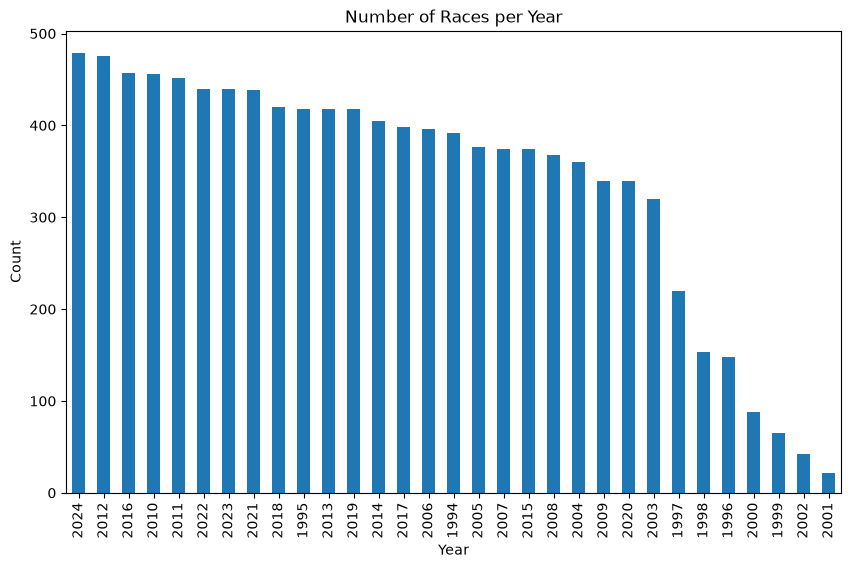

In [21]:
final_df_2['race_year'].value_counts().plot(kind='bar', title='Number of Races per Year', xlabel='Year', ylabel='Count', figsize=(10, 6))

In [22]:
final_df_2.head(10)

,raceId,driverId,constructorId,grid,podium,race_year,race_round,circuitId,quali_position,driver_nationality,circuit_country,constructor_name,driver_prev_position,driver_prev_podium,driver_avg_pos_last_5,pre_race_points,pre_race_wins,won_previous_race,is_home_race
0,1,1,1,18,0,2009,1,1,15.0,British,Australia,McLaren,5.0,0.0,5.6,0.0,0.0,0.0,0
1,1,2,2,9,0,2009,1,1,11.0,German,Australia,BMW Sauber,10.0,0.0,7.0,0.0,0.0,0.0,0
2,1,3,3,5,0,2009,1,1,5.0,German,Australia,Williams,12.0,0.0,10.8,0.0,0.0,0.0,0
3,1,4,4,10,0,2009,1,1,12.0,Spanish,Australia,Renault,2.0,1.0,2.4,0.0,0.0,0.0,0
4,1,5,1,12,0,2009,1,1,14.0,Finnish,Australia,McLaren,7.0,0.0,10.8,0.0,0.0,0.0,0
5,1,6,3,11,0,2009,1,1,13.0,Japanese,Australia,Williams,17.0,0.0,12.8,0.0,0.0,0.0,0
6,1,7,5,17,0,2009,1,1,20.0,French,Australia,Toro Rosso,14.0,0.0,13.4,0.0,0.0,0.0,0
7,1,8,6,7,0,2009,1,1,9.0,Finnish,Australia,Ferrari,3.0,1.0,6.6,0.0,0.0,0.0,0
8,1,9,2,4,0,2009,1,1,4.0,Polish,Australia,BMW Sauber,11.0,0.0,6.6,0.0,0.0,0.0,0
9,1,10,7,19,0,2009,1,1,6.0,German,Australia,Toyota,6.0,0.0,9.4,0.0,0.0,0.0,0


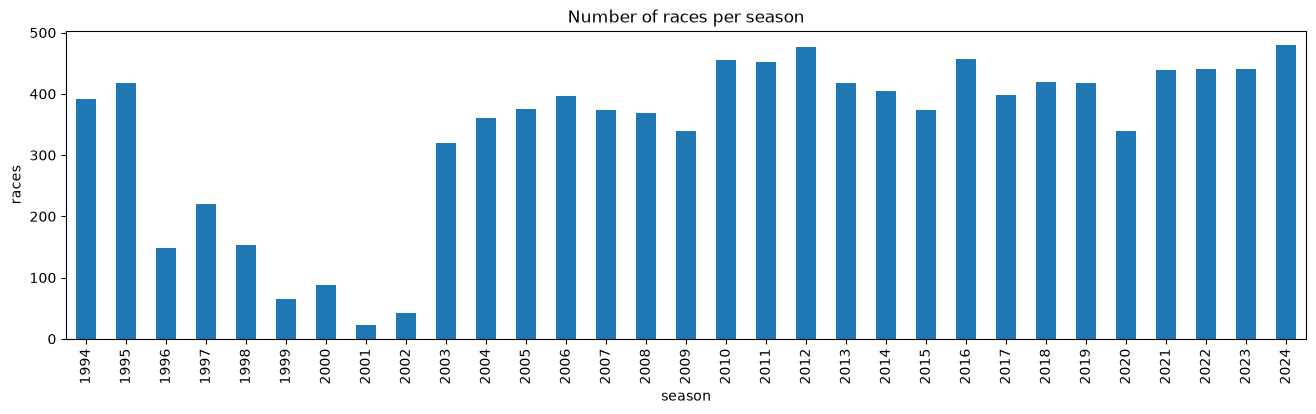

first season: 1994 | last season: 2024 | seasons: 31


In [23]:
import matplotlib.pyplot as plt
final_df_2['race_year'].value_counts().sort_index().plot(kind='bar', figsize=(16, 4))
plt.title('Number of races per season')
plt.xlabel('season'); plt.ylabel('races')
plt.show()
print('first season:', final_df_2['race_year'].min(), '| last season:', final_df_2['race_year'].max(),
      '| seasons:', final_df_2['race_year'].nunique())

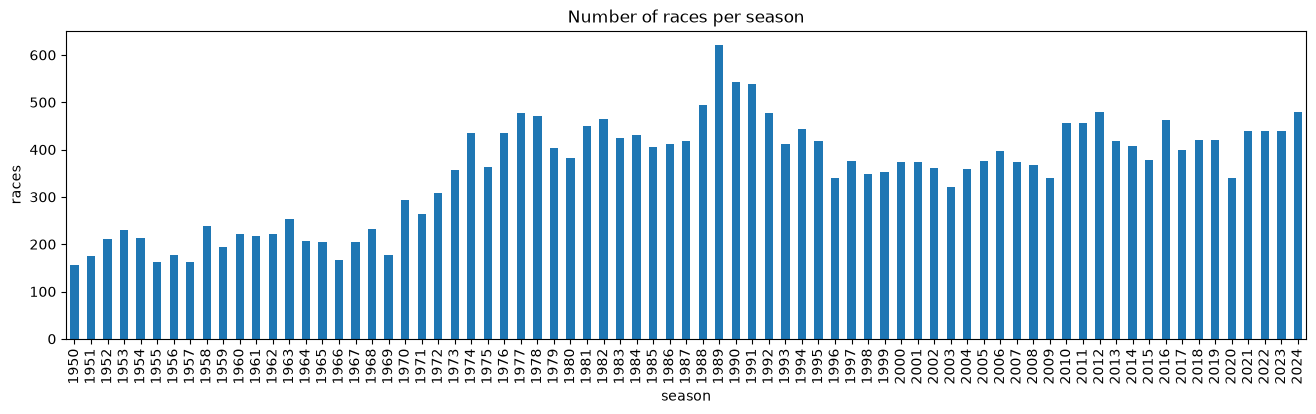

first season: 1950 | last season: 2024 | seasons: 75


In [24]:
import matplotlib.pyplot as plt
final_df['race_year'].value_counts().sort_index().plot(kind='bar', figsize=(16, 4))
plt.title('Number of races per season')
plt.xlabel('season'); plt.ylabel('races')
plt.show()
print('first season:', final_df['race_year'].min(), '| last season:', final_df['race_year'].max(),
      '| seasons:', final_df['race_year'].nunique())

In [27]:
final_df['race_year']

race_year
1989    620
1990    542
1991    539
1988    495
2012    480
       ... 
1951    175
1966    166
1957    163
1955    162
1950    156
Name: count, Length: 75, dtype: int64

In [29]:
final_df_2['race_year'].value_counts()

race_year
2024    479
2012    476
2016    457
2010    456
2011    452
2022    440
2023    440
2021    439
2018    420
1995    418
2013    418
2019    418
2014    405
2017    398
2006    396
1994    392
2005    376
2007    374
2015    374
2008    368
2004    360
2009    340
2020    340
2003    320
1997    220
1998    153
1996    148
2000     88
1999     65
2002     42
2001     22
Name: count, dtype: int64

In [30]:
import pandas as pd

# 1. Compute value counts for both columns
counts_2 = final_df_2['race_year'].value_counts()
counts_1 = final_df['race_year'].value_counts()

# 2. Combine them side-by-side, aligning by the 'race_year' index
comparison_df = pd.concat([counts_2, counts_1], axis=1, keys=['final_df_2', 'final_df'])

# 3. Fill missing years (where a year exists in one table but not the other) with 0
comparison_df = comparison_df.fillna(0).astype(int)

# 4. Sort chronologically by year
comparison_df = comparison_df.sort_index()

print(comparison_df)


           final_df_2  final_df
race_year                      
1950                0       156
1951                0       175
1952                0       212
1953                0       230
1954                0       213
...               ...       ...
2020              340       340
2021              439       440
2022              440       440
2023              440       440
2024              479       479

[75 rows x 2 columns]


In [31]:
comparison_df.to_csv('..\\ACL_9th-F1\\F1_clean\\race_year_comparison.csv')

We can see that before theyear 1994 there were no qualifying positions. Starting the 2003 3 year there are equal number of qualifying positions almost every year

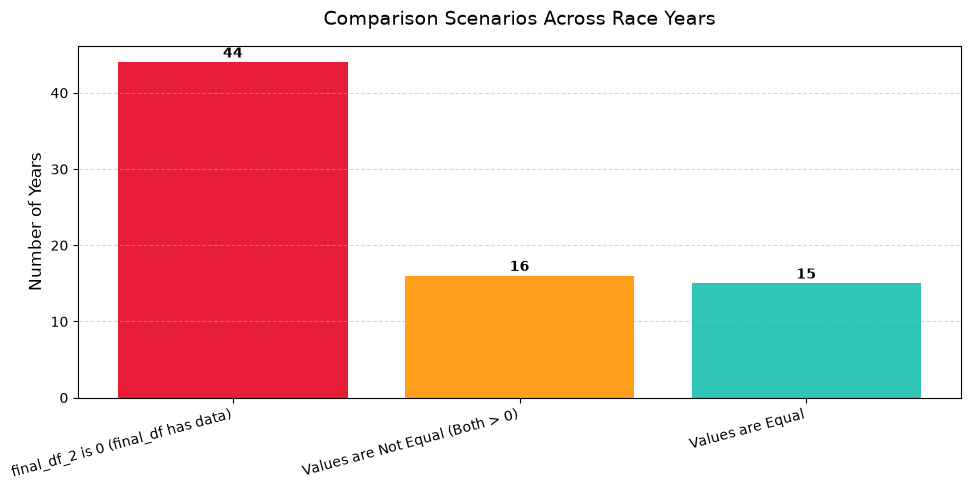

--- Years where final_df_2 is 0 ---
[1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993]


In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- 1. Prepare the aligned data ---
counts_2 = final_df_2["race_year"].value_counts()
counts_1 = final_df["race_year"].value_counts()

comparison_df = pd.concat(
    [counts_2, counts_1], axis=1, keys=["final_df_2", "final_df"]
)
comparison_df = comparison_df.fillna(0).astype(int)
comparison_df = comparison_df.sort_index()


# --- 2. Categorize the years based on your rules ---
def categorize_row(row):
    val_2 = row["final_df_2"]
    val_1 = row["final_df"]

    if val_2 == val_1:
        return "Values are Equal"
    elif val_2 == 0 and val_1 != 0:
        return "final_df_2 is 0 (final_df has data)"
    else:
        return "Values are Not Equal (Both > 0)"


comparison_df["Status"] = comparison_df.apply(categorize_row, axis=1)

# --- 3. Create the Visualization ---
# Count how many years fall into each specific scenario
status_counts = comparison_df["Status"].value_counts()

# Define explicit colors for visual clarity
color_map = {
    "Values are Equal": "#2ec4b6",  # Teal/Green
    "final_df_2 is 0 (final_df has data)": "#e71d36",  # Red
    "Values are Not Equal (Both > 0)": "#ff9f1c",  # Orange
}

colors = [color_map.get(status, "#333333") for status in status_counts.index]

plt.figure(figsize=(10, 5))
bars = plt.bar(status_counts.index, status_counts.values, color=colors)

# Add value labels on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.2,
        int(yval),
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.title("Comparison Scenarios Across Race Years", fontsize=14, pad=15)
plt.ylabel("Number of Years", fontsize=12)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

# --- Optional: Print out the years that mismatch ---
print("--- Years where final_df_2 is 0 ---")
print(
    comparison_df[
        comparison_df["Status"] == "final_df_2 is 0 (final_df has data)"
    ].index.tolist()
)


In [33]:
final_df[['driver_avg_pos_last_5', 'podium']].corr(method='spearman')


,driver_avg_pos_last_5,podium
driver_avg_pos_last_5,1.000000,-0.363164
podium,-0.363164,1.000000


--- Correlation Matrix (X features vs Y target) ---
                quali_position      grid    podium
quali_position        1.000000  0.943264 -0.486682
grid                  0.943264  1.000000 -0.364845
podium               -0.486682 -0.364845  1.000000


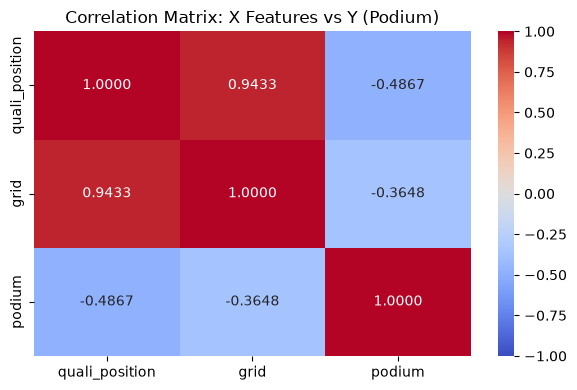

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your two X features and your single Y target variable
selected_columns = ["quali_position", "grid", "podium"]

# 2. Calculate the correlation matrix
matrix = final_df[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
print(matrix)

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(6, 4))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()


--- Correlation Matrix (X features vs Y target) ---
                       quali_position      grid    podium  \
quali_position               1.000000  0.943264 -0.486682   
grid                         0.943264  1.000000 -0.364845   
podium                      -0.486682 -0.364845  1.000000   
driver_avg_pos_last_5        0.682443  0.317662 -0.349465   

                       driver_avg_pos_last_5  
quali_position                      0.682443  
grid                                0.317662  
podium                             -0.349465  
driver_avg_pos_last_5               1.000000  


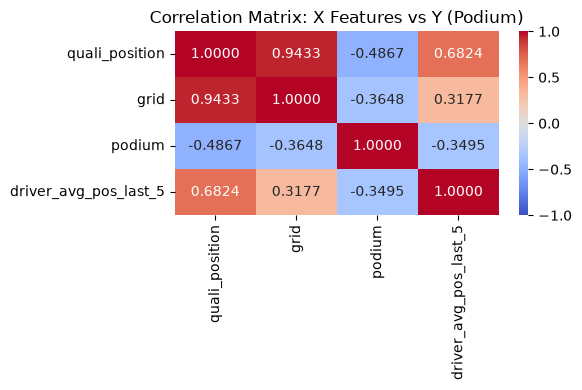

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your two X features and your single Y target variable
selected_columns = ["quali_position", "grid", "podium","driver_avg_pos_last_5"]

# 2. Calculate the correlation matrix
matrix = final_df[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
print(matrix)

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(6, 4))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()


--- Correlation Matrix (X features vs Y target) ---
                       quali_position      grid    podium  \
quali_position               1.000000  0.943264 -0.486682   
grid                         0.943264  1.000000 -0.364845   
podium                      -0.486682 -0.364845  1.000000   
driver_avg_pos_last_5        0.682443  0.317662 -0.349465   
pre_race_points             -0.473221 -0.291035  0.317099   
pre_race_wins               -0.359557 -0.284829  0.370284   
won_previous_race           -0.268635 -0.206662  0.254660   
is_home_race                 0.000759  0.059211 -0.019443   
driver_prev_position         0.508454  0.240681 -0.269431   
driver_prev_podium          -0.410729 -0.311441  0.350418   

                       driver_avg_pos_last_5  pre_race_points  pre_race_wins  \
quali_position                      0.682443        -0.473221      -0.359557   
grid                                0.317662        -0.291035      -0.284829   
podium                             -

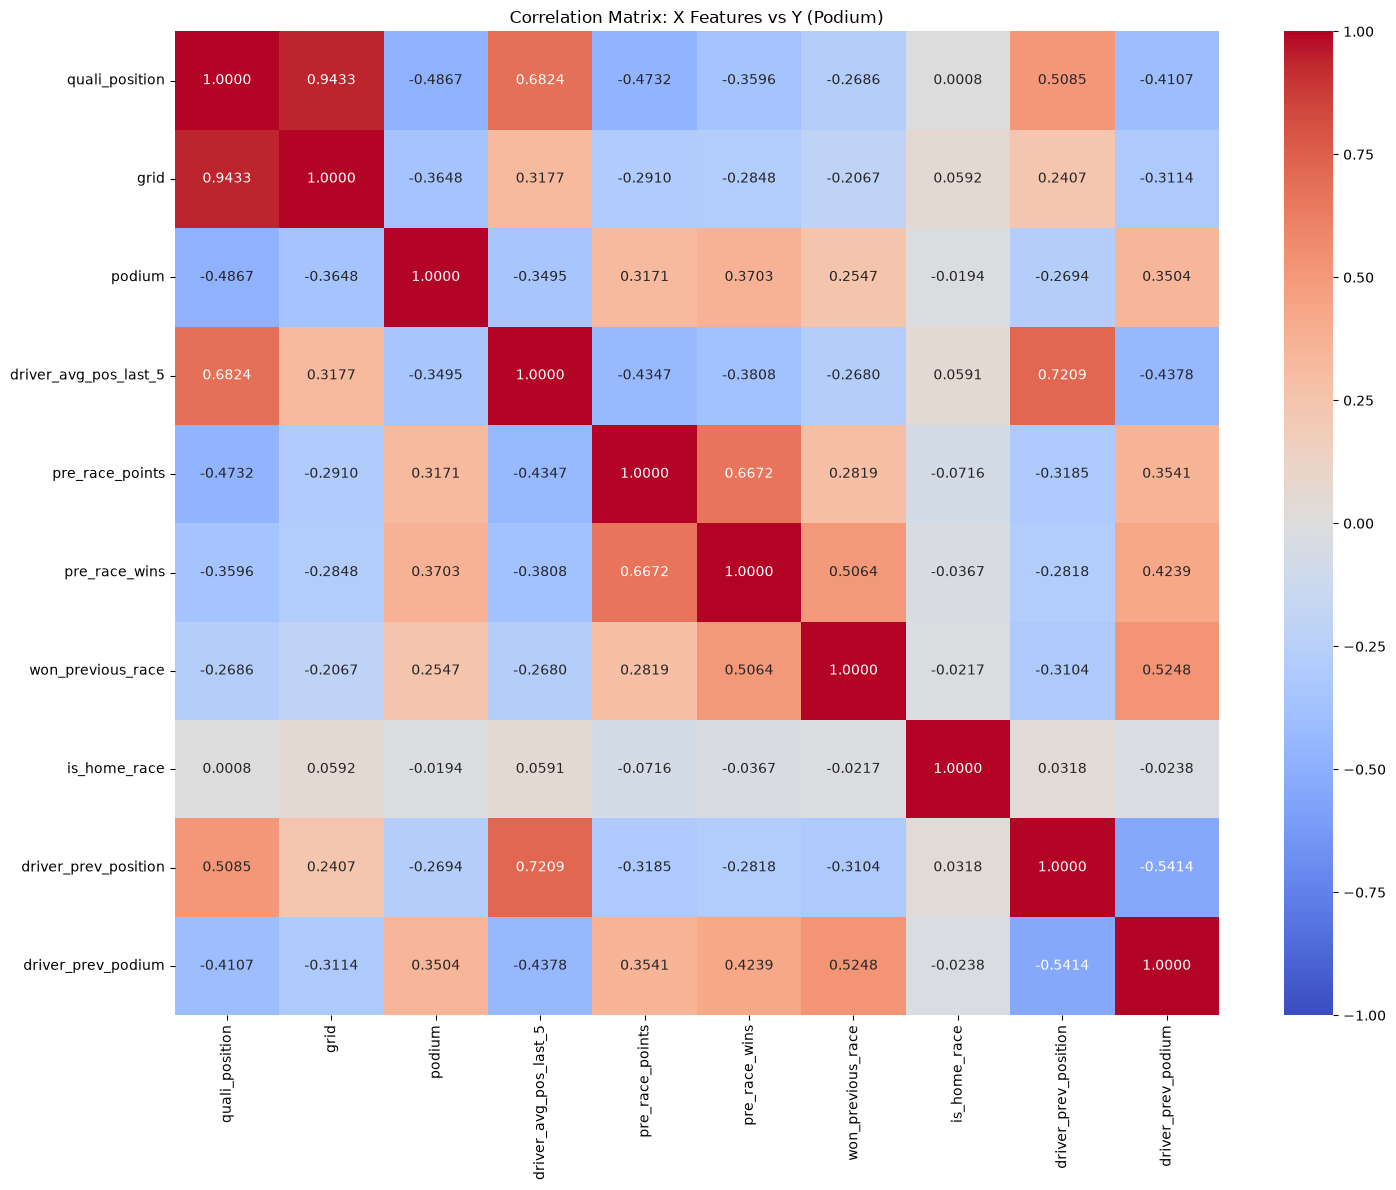

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your two X features and your single Y target variable
selected_columns = ["quali_position", "grid", "podium","driver_avg_pos_last_5","pre_race_points","pre_race_wins","won_previous_race","is_home_race","driver_prev_position","driver_prev_podium"]

# 2. Calculate the correlation matrix
matrix = final_df[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
print(matrix)

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(15, 12))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()


In [45]:
temp_grid = final_df['grid'].replace(0, 22)
df_replaced_qual=final_df.copy()
df_replaced_qual['quali_position'] = df_replaced_qual['quali_position'].fillna(temp_grid)
df_replaced_qual['driver_prev_position'] = df_replaced_qual['driver_prev_position'].fillna(20)
df_replaced_qual['driver_avg_pos_last_5'] = df_replaced_qual['driver_avg_pos_last_5'].fillna(20)
print(df_replaced_qual.isnull().sum())

raceId                   0
driverId                 0
constructorId            0
grid                     0
podium                   0
race_year                0
race_round               0
circuitId                0
quali_position           0
driver_nationality       0
circuit_country          0
constructor_name         0
driver_prev_position     0
driver_prev_podium       0
driver_avg_pos_last_5    0
pre_race_points          0
pre_race_wins            0
won_previous_race        0
is_home_race             0
dtype: int64


--- Correlation Matrix (X features vs Y target) ---
                       quali_position      grid    podium  \
quali_position               1.000000  0.723167 -0.446894   
grid                         0.723167  1.000000 -0.364845   
podium                      -0.446894 -0.364845  1.000000   
driver_avg_pos_last_5        0.614615  0.319461 -0.351257   
pre_race_points             -0.379168 -0.291035  0.317099   
pre_race_wins               -0.350077 -0.284829  0.370284   
won_previous_race           -0.249675 -0.206662  0.254660   
is_home_race                 0.067573  0.059211 -0.019443   
driver_prev_position         0.472521  0.244618 -0.273774   
driver_prev_podium          -0.389410 -0.311441  0.350418   

                       driver_avg_pos_last_5  pre_race_points  pre_race_wins  \
quali_position                      0.614615        -0.379168      -0.350077   
grid                                0.319461        -0.291035      -0.284829   
podium                             -

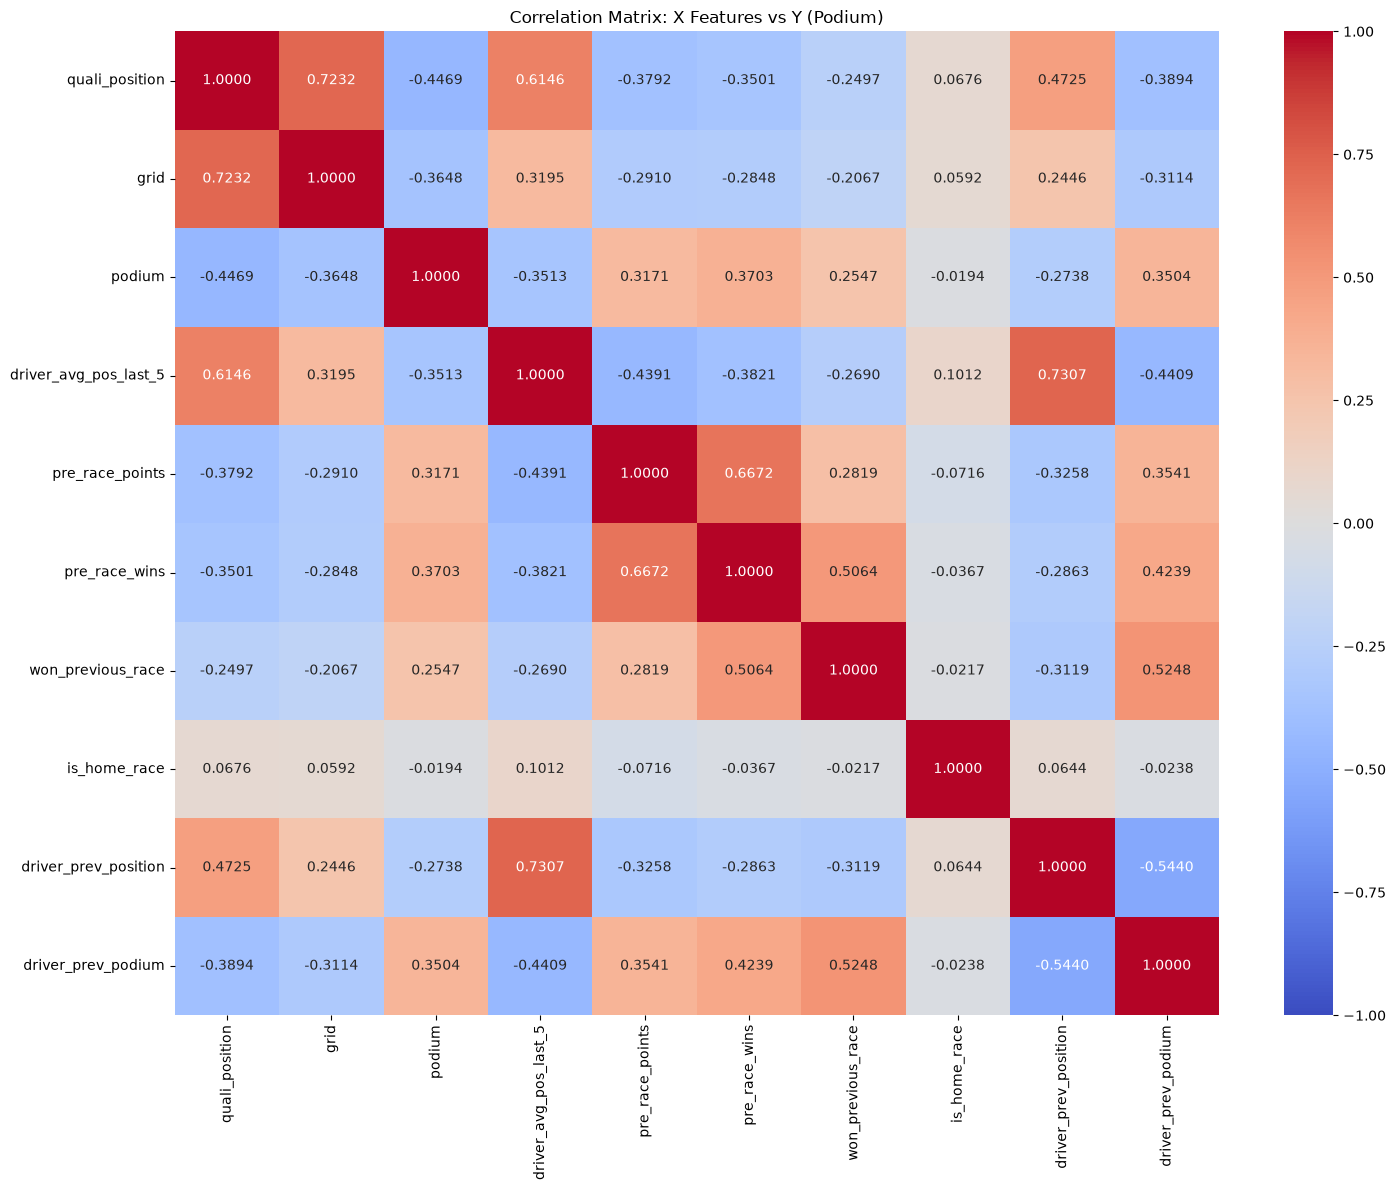

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your two X features and your single Y target variable
selected_columns = ["quali_position", "grid", "podium","driver_avg_pos_last_5","pre_race_points","pre_race_wins","won_previous_race","is_home_race","driver_prev_position","driver_prev_podium"]

# 2. Calculate the correlation matrix
matrix = df_replaced_qual[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
print(matrix)

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(15, 12))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()


--- Correlation Matrix (X features vs Y target) ---
                       quali_position      grid    podium  \
quali_position               1.000000  0.655183 -0.437331   
grid                         0.655183  1.000000 -0.364845   
podium                      -0.437331 -0.364845  1.000000   
driver_avg_pos_last_5        0.637962  0.319461 -0.351257   
pre_race_points             -0.372953 -0.291035  0.317099   
pre_race_wins               -0.342232 -0.284829  0.370284   
won_previous_race           -0.243736 -0.206662  0.254660   
is_home_race                 0.066089  0.059211 -0.019443   
driver_prev_position         0.490517  0.244618 -0.273774   
driver_prev_podium          -0.381959 -0.311441  0.350418   

                       driver_avg_pos_last_5  pre_race_points  pre_race_wins  \
quali_position                      0.637962        -0.372953      -0.342232   
grid                                0.319461        -0.291035      -0.284829   
podium                             -

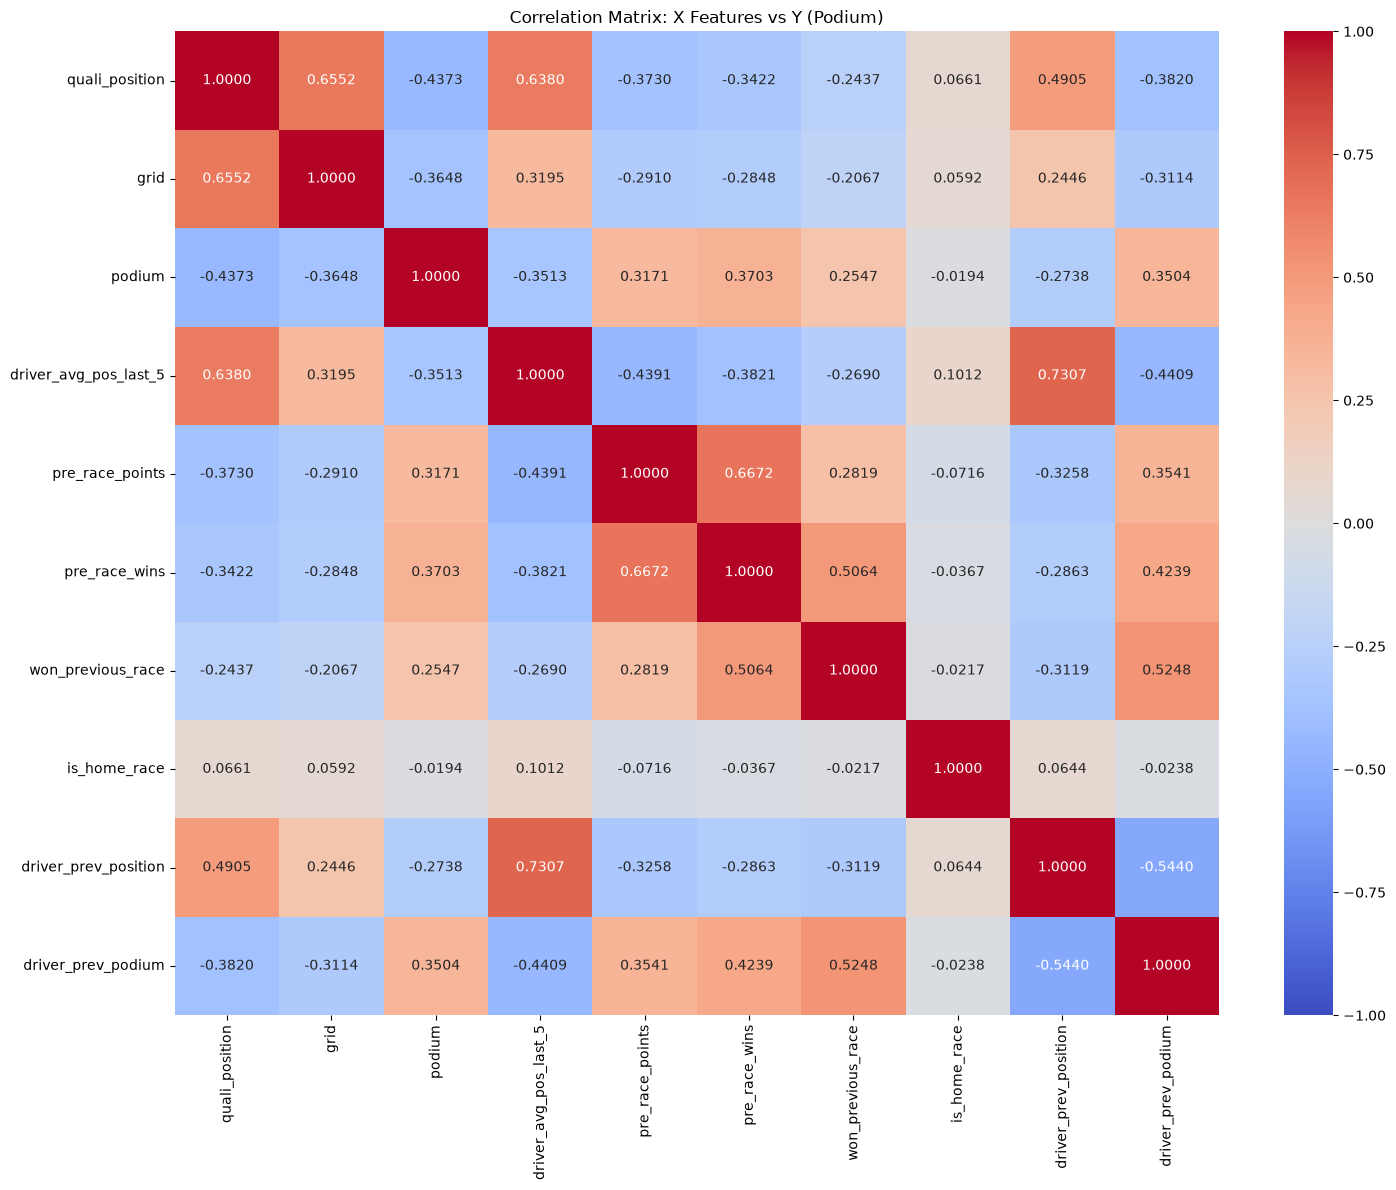

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your two X features and your single Y target variable
selected_columns = ["quali_position", "grid", "podium","driver_avg_pos_last_5","pre_race_points","pre_race_wins","won_previous_race","is_home_race","driver_prev_position","driver_prev_podium"]

# 2. Calculate the correlation matrix
matrix = df_replaced_qual[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
print(matrix)

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(15, 12))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()


In [49]:
final_df= pd.read_csv('..\\ACL_9th-F1\\F1_clean\\FINAL_training_table.csv')
last_slot = final_df.groupby('raceId')['grid'].transform('max')            # last grid slot of each race
temp_grid = final_df['grid'].where(final_df['grid'] != 0, last_slot + 1)   # grid 0 -> behind the last car of that race
df_replaced_qual=final_df.copy()
df_replaced_qual['quali_position'] = df_replaced_qual['quali_position'].fillna(temp_grid)
df_replaced_qual['driver_prev_position'] = df_replaced_qual['driver_prev_position'].fillna(20)
df_replaced_qual['driver_avg_pos_last_5'] = df_replaced_qual['driver_avg_pos_last_5'].fillna(20)
print(df_replaced_qual.isnull().sum())

raceId                   0
driverId                 0
constructorId            0
grid                     0
podium                   0
race_year                0
race_round               0
circuitId                0
quali_position           0
driver_nationality       0
circuit_country          0
constructor_name         0
driver_prev_position     0
driver_prev_podium       0
driver_avg_pos_last_5    0
pre_race_points          0
pre_race_wins            0
won_previous_race        0
is_home_race             0
dtype: int64


--- Correlation Matrix (X features vs Y target) ---
                       quali_position      grid    podium  \
quali_position               1.000000  0.655183 -0.437331   
grid                         0.655183  1.000000 -0.364845   
podium                      -0.437331 -0.364845  1.000000   
driver_avg_pos_last_5        0.637962  0.319461 -0.351257   
pre_race_points             -0.372953 -0.291035  0.317099   
pre_race_wins               -0.342232 -0.284829  0.370284   
won_previous_race           -0.243736 -0.206662  0.254660   
is_home_race                 0.066089  0.059211 -0.019443   
driver_prev_position         0.490517  0.244618 -0.273774   
driver_prev_podium          -0.381959 -0.311441  0.350418   

                       driver_avg_pos_last_5  pre_race_points  pre_race_wins  \
quali_position                      0.637962        -0.372953      -0.342232   
grid                                0.319461        -0.291035      -0.284829   
podium                             -

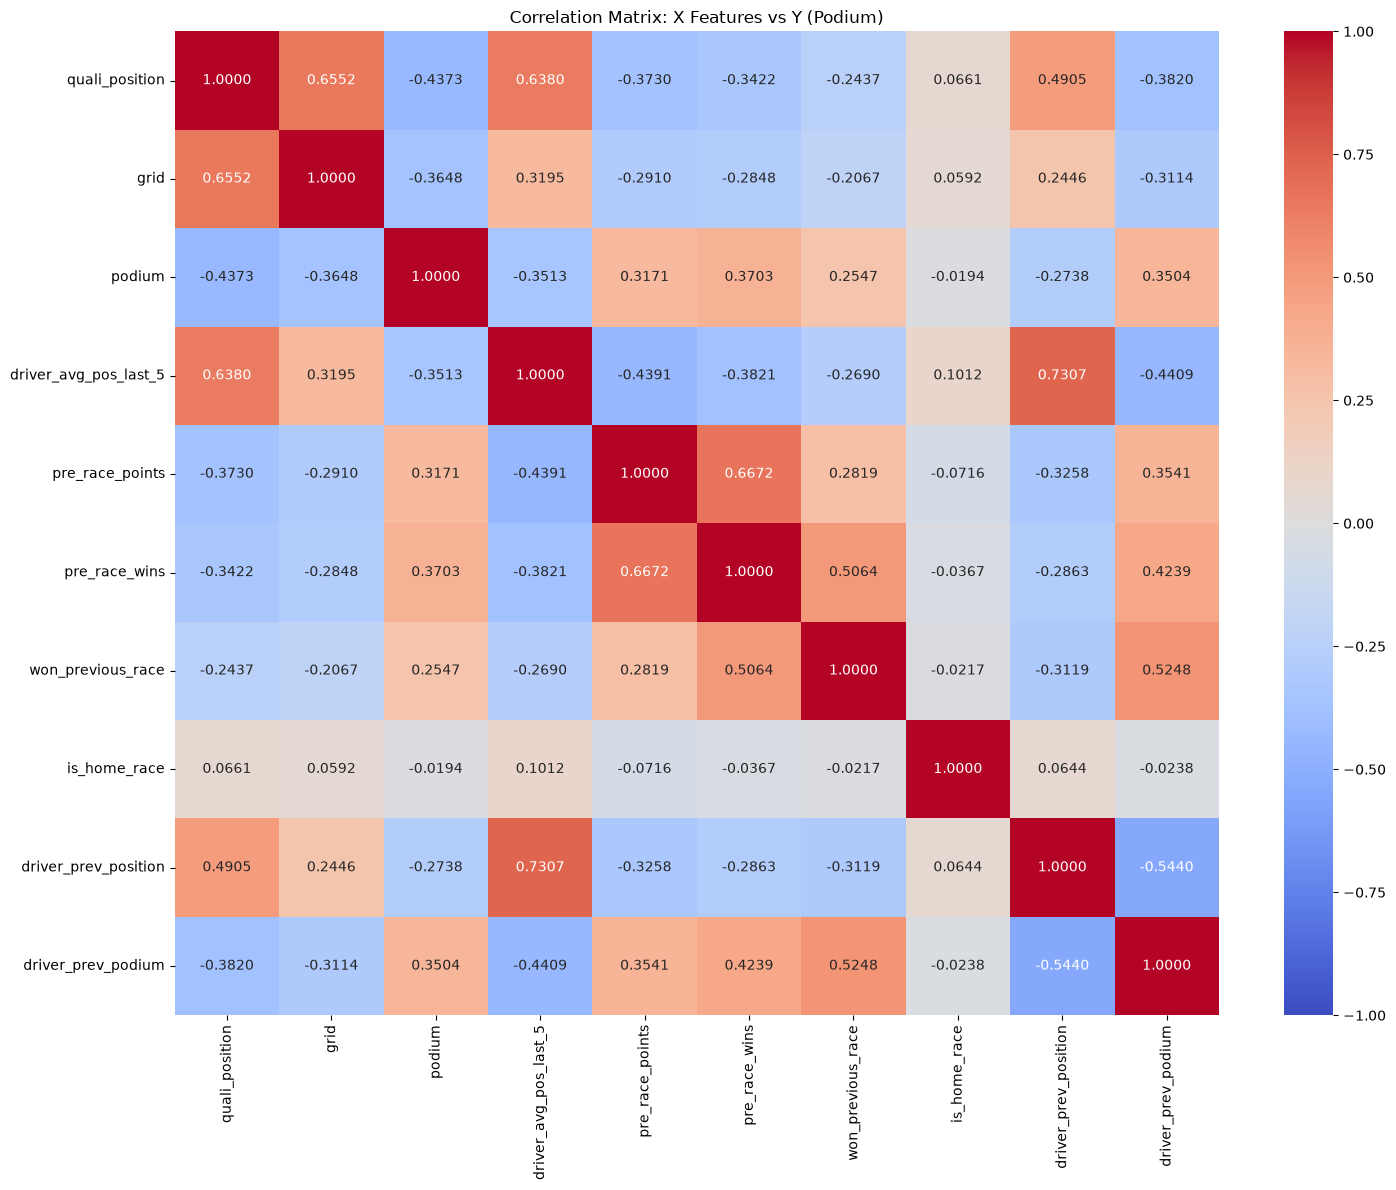

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your two X features and your single Y target variable
selected_columns = ["quali_position", "grid", "podium","driver_avg_pos_last_5","pre_race_points","pre_race_wins","won_previous_race","is_home_race","driver_prev_position","driver_prev_podium"]

# 2. Calculate the correlation matrix
matrix = df_replaced_qual[selected_columns].corr()

print("--- Correlation Matrix (X features vs Y target) ---")
print(matrix)

# 3. Plot a clean heatmap to visualize the relationships
plt.figure(figsize=(15, 12))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: X Features vs Y (Podium)")
plt.tight_layout()
plt.show()


--- Correlation Matrix (From 2021 Onward) ---
                       quali_position      grid    podium  \
quali_position               1.000000  0.844362 -0.516739   
grid                         0.844362  1.000000 -0.464986   
podium                      -0.516739 -0.464986  1.000000   
driver_avg_pos_last_5        0.671805  0.589351 -0.480173   
pre_race_points             -0.524631 -0.456865  0.447349   
pre_race_wins               -0.349002 -0.296885  0.414910   
won_previous_race           -0.276447 -0.254004  0.314357   
is_home_race                -0.060061 -0.047858  0.042901   
driver_prev_position         0.546822  0.481075 -0.407302   
driver_prev_podium          -0.427626 -0.383856  0.411707   

                       driver_avg_pos_last_5  pre_race_points  pre_race_wins  \
quali_position                      0.671805        -0.524631      -0.349002   
grid                                0.589351        -0.456865      -0.296885   
podium                             -0.4801

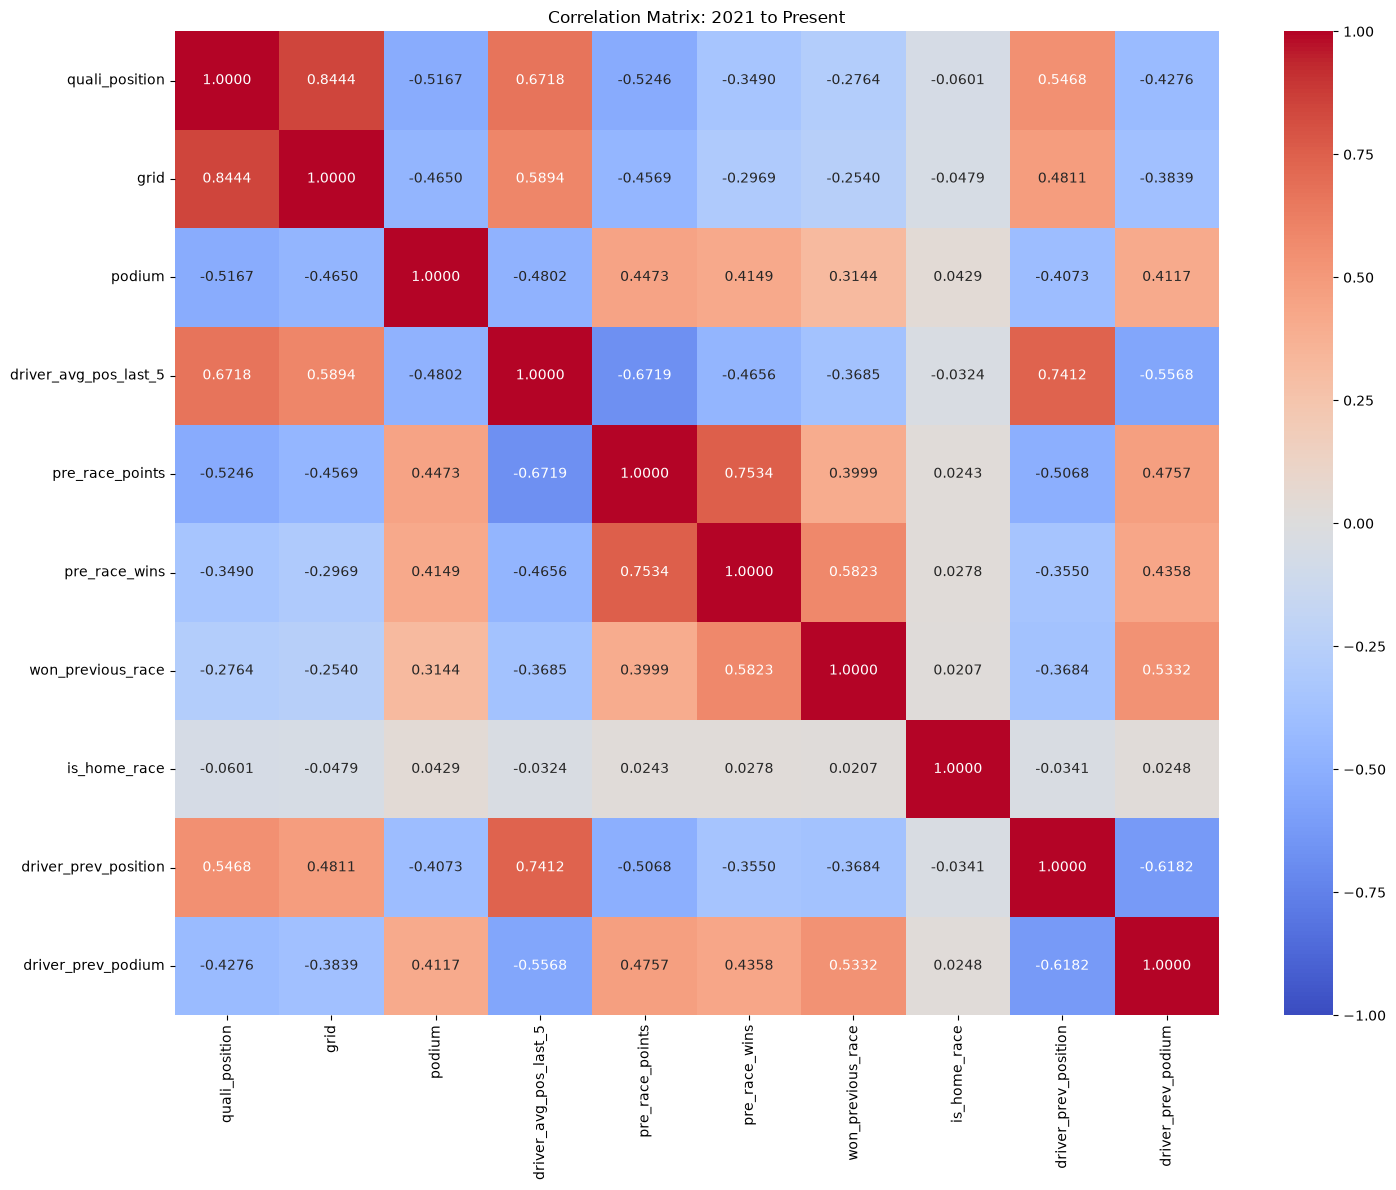

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define your selected columns (X features and Y target)
selected_columns = [
    "quali_position",
    "grid",
    "podium",
    "driver_avg_pos_last_5",
    "pre_race_points",
    "pre_race_wins",
    "won_previous_race",
    "is_home_race",
    "driver_prev_position",
    "driver_prev_podium",
]

# 2. Filter the DataFrame to start from race_year 2021
df_2021_plus = df_replaced_qual[df_replaced_qual["race_year"] >= 2021]

# 3. Calculate the correlation matrix on the filtered data
matrix = df_2021_plus[selected_columns].corr()

print("--- Correlation Matrix (From 2021 Onward) ---")
print(matrix)

# 4. Plot the heatmap
plt.figure(figsize=(15, 12))
sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".4f")
plt.title("Correlation Matrix: 2021 to Present")
plt.tight_layout()
plt.show()
